In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split, KFold
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import numpy as np
import seaborn as sns
import optuna
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.ensemble import AdaBoostRegressor, RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
from sklearn.neural_network import MLPRegressor
from catboost import CatBoostRegressor
from math import pi
import matplotlib.pyplot as plt

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

# --------------------------------------------------
# 1. Load data
# --------------------------------------------------
data = pd.read_csv("hpc.csv")


X = data.iloc[:, :-1]
y = data.iloc[:, -1]

# --------------------------------------------------
# 4. Train-test split
# --------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

data.describe()

,C,BFS,FA,W,SP,CA,FAg,Age,CS
count,2171.000000,2171.000000,2171.000000,2171.000000,2171.000000,2171.000000,2171.000000,2171.000000,2171.000000
mean,268.384569,74.372962,66.011515,182.850207,4.704933,998.744357,743.526209,64.479963,37.990470
std,110.122893,99.810911,90.817305,32.948553,5.724433,119.519005,110.597748,92.640602,20.368642
min,70.000000,0.000000,0.000000,105.000000,0.000000,723.000000,280.000000,1.000000,1.100000
25%,180.000000,0.000000,0.000000,159.000000,0.000000,932.000000,684.000000,7.000000,23.695000
50%,250.000000,0.000000,0.000000,182.000000,3.300000,1005.600000,750.000000,28.000000,35.300000
75%,347.000000,141.300000,123.000000,203.100000,8.000000,1097.000000,804.000000,90.000000,49.800000
max,702.000000,440.000000,544.000000,295.000000,35.100000,1218.000000,992.600000,365.000000,124.500000


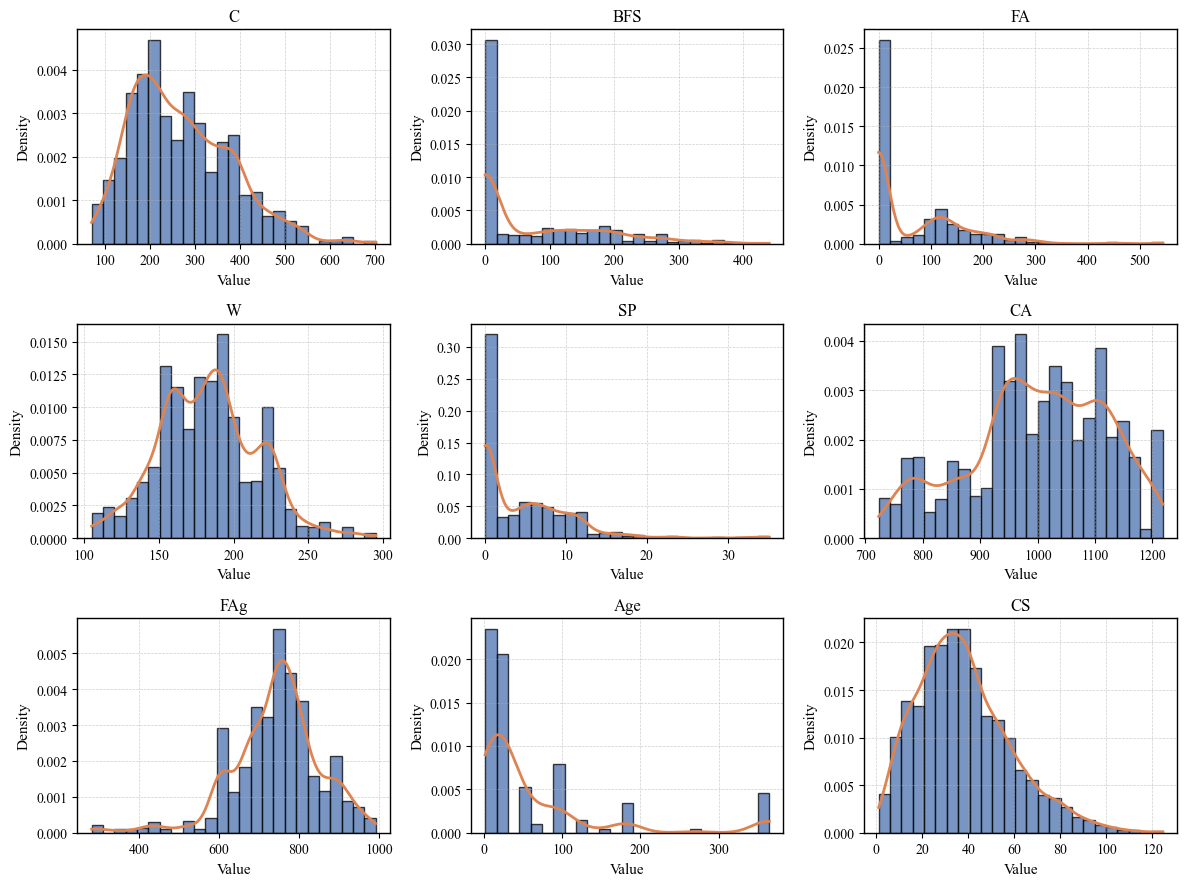

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from sklearn.model_selection import train_test_split


# ---------- Plot settings (Journal style) ----------
plt.rcParams.update({
    "font.family": "Times New Roman",
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 1,
})

fig, axes = plt.subplots(3, 3, figsize=(12, 9))

axes = axes.ravel()

for i in range(9):
    col_data = data.iloc[:, i]

    # Histogram
    axes[i].hist(
        col_data,
        bins=25,
        density=True,
        color="#4C72B0",
        edgecolor="black",
        alpha=0.75
    )

    # KDE
    kde = gaussian_kde(col_data)
    xx = np.linspace(col_data.min(), col_data.max(), 300)
    yy = kde(xx)
    axes[i].plot(xx, yy, color="#DD8452", linewidth=2)

    # Titles & labels
    axes[i].set_title(data.columns[i], pad=6)
    axes[i].set_ylabel("Density")
    axes[i].set_xlabel("Value")

    # Grid (light, journal style)
    axes[i].grid(True, linestyle="--", linewidth=0.5, alpha=0.6)

plt.tight_layout()
plt.show()


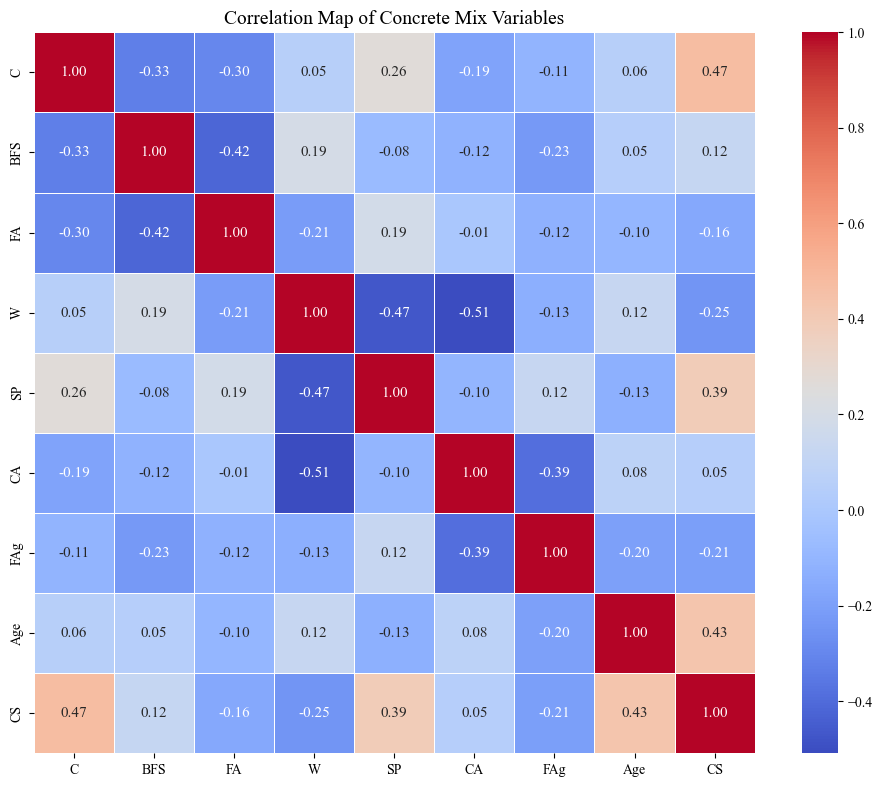

In [4]:
# Correlation map of concrete mix variables and cost. 
import seaborn as sns
corr = data.iloc[:,:9].corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True, linewidths=0.5)
plt.title("Correlation Map of Concrete Mix Variables", fontsize=14)
plt.tight_layout()
plt.show()


In [ ]:
# Tuning the hyperparameters of the AdaBoostRegressor model

def objective(trial):

    base_estimator = DecisionTreeRegressor(
        max_depth=trial.suggest_int("max_depth", 1, 10),
        min_samples_split=trial.suggest_int("min_samples_split", 2, 20),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),
        random_state=42
    )

    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 1000),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 1.0, log=True),
        "loss": trial.suggest_categorical("loss", ["linear", "square", "exponential"]),
        "estimator": base_estimator,
        "random_state": 42
    }

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    rmse_list = []

    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

        model = AdaBoostRegressor(**params)
        model.fit(X_tr, y_tr)

        y_pred = model.predict(X_val)
        rmse_list.append(np.sqrt(mean_squared_error(y_val, y_pred)))

    return np.mean(rmse_list)
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)
for key, value in study.best_params.items():
    print(f"{key}: {value}")

In [20]:
# Evaluating the AdaBoostRegressor model
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
# hpc
final_model = AdaBoostRegressor(
    n_estimators=461,
    learning_rate= 0.011936645,
    loss="square",
    random_state=42,
    estimator=DecisionTreeRegressor(
        max_depth=9,
        min_samples_split=9,
        min_samples_leaf=1,
        random_state=42
    )
)

final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)
y_AdaBoostRegressor=y_pred
model_AdaBoostRegressor=final_model


r2 = r2_score(y_test, y_pred) #Coefficient of determination
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
epsilon = 1e-8   
mean_absolute_relative_error = np.mean(np.abs((y_test - y_pred) / (y_test + epsilon)))
mean_square_relative_error=np.mean(((y_test - y_pred) / (y_test + epsilon))**2)
Root_mean_squared_relative_error=np.sqrt(mean_square_relative_error)
Relative_root_mean_square_error=rmse/np.sum(y_test)*100
mean_bias_error=np.mean(y_test - y_pred)
max_absolute_relative_error=np.max(np.abs((y_test - y_pred) / (y_test + epsilon)))
std_diff = np.std(y_test - y_pred, ddof=0)
uncertainty_95=np.sqrt(1.96 * (std_diff**2 + rmse**2))
r2, np.corrcoef(y_test, y_pred)[0,1], mse, rmse, mae

final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)
y_CatBoostRegressor=y_pred
model_CatBoostRegressor = final_model

r2 = r2_score(y_test, y_pred) #Coefficient of determination
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2, np.corrcoef(y_test, y_pred)[0,1], mse, rmse, mae

(0.9131605465050526,
 np.float64(0.9574914876695633),
 34.82448029785171,
 np.float64(5.901227016295145),
 4.313847643998627)

In [7]:
import json

model = final_model
def export_tree(estimator):
    t = estimator.tree_
    return {
        "children_left": t.children_left.tolist(),
        "children_right": t.children_right.tolist(),
        "feature": t.feature.tolist(),
        "threshold": t.threshold.tolist(),
        "value": t.value[:, 0, 0].tolist()
    }

model_json = {
    "model_type": "AdaBoostRegressor",
    "feature_names": list(X.columns) if hasattr(X, "columns") else
                     [f"f{i}" for i in range(X_1.shape[1])],
    "n_features": int(X_train.shape[1]),
    "aggregation": "weighted_median",
    "trees": [export_tree(est) for est in model.estimators_],
    "estimator_weights": model.estimator_weights_.tolist()
}

with open("adaboost.json", "w", encoding="utf-8") as f:
    json.dump(model_json, f, separators=(",", ":"))

# Check the exported tree data against scikit-learn's own predictions
def predict_tree(tree_data, x):
    node = 0
    while tree_data["children_left"][node] != -1:
        feature_idx = tree_data["feature"][node]
        if x[feature_idx] <= tree_data["threshold"][node]:
            node = tree_data["children_left"][node]
        else:
            node = tree_data["children_right"][node]
    return tree_data["value"][node]

def weighted_median(values, weights):
    order = np.argsort(values)
    values = np.asarray(values)[order]
    weights = np.asarray(weights)[order]
    cutoff = weights.sum() / 2.0
    idx = np.searchsorted(np.cumsum(weights), cutoff, side="left")
    return float(values[min(idx, len(values) - 1)])

def exported_predict(x):
    predictions = [
        predict_tree(tree, x)
        for tree in model_json["trees"]
    ]
    weights = model_json["estimator_weights"]
    return weighted_median(predictions, weights)

X_check = X_test.to_numpy() if hasattr(X_test, "to_numpy") else np.asarray(X_test)
sklearn_preds = np.asarray(model.predict(X_test))
export_preds = np.asarray([exported_predict(row) for row in X_check])

print("Model R2 on test set:", model.score(X_test, y_test))
print("Maximum export prediction error:",
      float(np.max(np.abs(sklearn_preds - export_preds))))
print("Saved: adaboost.json")


Model R2 on test set: 0.9131605465050526
Maximum export prediction error: 0.07025000000000858
Saved: adaboost.json


In [ ]:
# Tuning the hyperparameters of the RandomForestRegressor

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1500),
        "max_depth": trial.suggest_int("max_depth", 3, 30),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
        
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", None]),
        
        "bootstrap": trial.suggest_categorical("bootstrap", [True, False]),
        "random_state": 42,
        "n_jobs": -1
    }

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    rmse_list = []

    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

        model = RandomForestRegressor(**params)
        model.fit(X_tr, y_tr)

        y_pred = model.predict(X_val)
        rmse_list.append(np.sqrt(mean_squared_error(y_val, y_pred)))

    return np.mean(rmse_list)

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)
for key, value in study.best_params.items():
    print(f"{key}: {value}")


In [19]:
# Evaluating the RandomForestRegressor model
from sklearn.ensemble import RandomForestRegressor
# hpc
final_model = RandomForestRegressor(
    n_estimators=467,
    max_depth=30,
    min_samples_split=6,
    min_samples_leaf=1,
    max_features='log2',
    bootstrap=False,
    random_state=42,    
)

final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)
y_RandomForestRegressor=y_pred
model_RandomForestRegressor=final_model

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)
mare = np.mean(np.abs((y_test - y_pred) / y_test))

r2 = r2_score(y_test, y_pred) #Coefficient of determination
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
epsilon = 1e-8   
mean_absolute_relative_error = np.mean(np.abs((y_test - y_pred) / (y_test + epsilon)))
mean_square_relative_error=np.mean(((y_test - y_pred) / (y_test + epsilon))**2)
Root_mean_squared_relative_error=np.sqrt(mean_square_relative_error)
Relative_root_mean_square_error=rmse/np.sum(y_test)
mean_bias_error=np.mean(y_test - y_pred)
max_absolute_relative_error=np.max(np.abs((y_test - y_pred) / (y_test + epsilon)))
std_diff = np.std(y_test - y_pred, ddof=0)
uncertainty_95=np.sqrt(1.96 * (std_diff**2 + rmse**2))
r2, np.corrcoef(y_test, y_pred)[0,1], mse, rmse, mae

final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)
y_CatBoostRegressor=y_pred
model_CatBoostRegressor = final_model

r2 = r2_score(y_test, y_pred) #Coefficient of determination
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2, np.corrcoef(y_test, y_pred)[0,1], mse, rmse, mae

(0.9360596544072706,
 np.float64(0.9709812379386896),
 25.641447702816233,
 np.float64(5.0637385105094275),
 3.512118910065557)

In [10]:
model = final_model

def export_tree(estimator):
    tree = estimator.tree_

    return {
        "children_left": tree.children_left.tolist(),
        "children_right": tree.children_right.tolist(),
        "feature": tree.feature.tolist(),
        "threshold": tree.threshold.tolist(),
        "value": tree.value[:, 0, 0].tolist()
    }

feature_names = (
    list(X.columns)
    if hasattr(X, "columns")
    else [f"f{i}" for i in range(X.shape[1])]
)

model_json = {
    "model_type": "RandomForestRegressor",
    "n_features": int(X_train.shape[1]),
    "feature_names": feature_names,
    "n_estimators": len(model.estimators_),
    "trees": [export_tree(est) for est in model.estimators_]
}

with open("random_forest.json", "w", encoding="utf-8") as f:
    json.dump(model_json, f, ensure_ascii=False, separators=(",", ":"))

print("Saved: random_forest.json")
print("Number of trees:", len(model.estimators_))


Saved: random_forest.json
Number of trees: 467


In [ ]:
# Tuning the hyperparameters of the SVR

from sklearn.svm import SVR
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import numpy as np

def objective(trial):
    params = {
        "C": trial.suggest_float("C", 0.1, 100, log=True),
        "epsilon": trial.suggest_float("epsilon", 0.001, 1.0, log=True),
        "gamma": trial.suggest_float("gamma", 1e-4, 1e-1, log=True),
        "kernel": trial.suggest_categorical("kernel", ["rbf", "poly", "sigmoid"])
    }

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    rmse_list = []

    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("svr", SVR(**params))
        ])

        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        y_SVR=y_pred

        rmse_list.append(np.sqrt(mean_squared_error(y_val, y_pred)))

    return np.mean(rmse_list)
import optuna
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)
for key, value in study.best_params.items():
    print(f"{key}: {value}")


In [18]:
# Evaluating the SVR model

from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error,mean_squared_error


# hpc
final_model = Pipeline([
            ("scaler", StandardScaler()),
            ("svr", SVR(C=30.61330396, 
                        epsilon=0.013310678,
                        gamma=0.090972353,
                        kernel='rbf'))
        ])

final_model.fit(X_train, y_train)
model_SVR=final_model
y_pred = final_model.predict(X_test)
y_SVR = y_pred
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mare = np.mean(np.abs((y_test - y_pred) / y_test))
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

r2 = r2_score(y_test, y_pred) #Coefficient of determination
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
epsilon = 1e-8   
mean_absolute_relative_error = np.mean(np.abs((y_test - y_pred) / (y_test + epsilon)))
mean_square_relative_error=np.mean(((y_test - y_pred) / (y_test + epsilon))**2)
Root_mean_squared_relative_error=np.sqrt(mean_square_relative_error)
Relative_root_mean_square_error=rmse/np.sum(y_test)
mean_bias_error=np.mean(y_test - y_pred)
max_absolute_relative_error=np.max(np.abs((y_test - y_pred) / (y_test + epsilon)))
std_diff = np.std(y_test - y_pred, ddof=0)
uncertainty_95=np.sqrt(1.96 * (std_diff**2 + rmse**2))
r2, np.corrcoef(y_test, y_pred)[0,1], mse, rmse, mae

final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)
y_CatBoostRegressor=y_pred
model_CatBoostRegressor = final_model

r2 = r2_score(y_test, y_pred) #Coefficient of determination
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2, np.corrcoef(y_test, y_pred)[0,1], mse, rmse, mae

(0.8652555090764797,
 np.float64(0.9329097540498317),
 54.03542607143666,
 np.float64(7.3508792719943825),
 5.264507680230794)

In [13]:
import json
model = final_model
scaler = model.named_steps["scaler"]
svr = model.named_steps["svr"]

# Save all parameters needed for inference
model_json = {
    "model_type": "SVR_RBF",
    "feature_names": (
        list(X.columns)
        if hasattr(X, "columns")
        else [f"f{i}" for i in range(X.shape[1])]
    ),
    "n_features": int(X_train.shape[1]),
    "scaler_mean": scaler.mean_.tolist(),
    "scaler_scale": scaler.scale_.tolist(),
    "support_vectors": svr.support_vectors_.tolist(),
    "dual_coef": svr.dual_coef_[0].tolist(),
    "intercept": float(svr.intercept_[0]),
    "gamma": float(svr._gamma)
}

with open("svr.json", "w", encoding="utf-8") as f:
    json.dump(model_json, f, separators=(",", ":"))


In [ ]:
# Tuning the hyperparameters of the XGBRegressor

from xgboost import XGBRegressor
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 1500),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "subsample": trial.suggest_float("subsample", 0.3, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3),
        "random_state": 42,
        "n_jobs": -1
    }

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    rmse_list = []

    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

        model = XGBRegressor(**params)
        model.fit(X_tr, y_tr)

        y_pred = model.predict(X_val)
        rmse_list.append(np.sqrt(mean_squared_error(y_val, y_pred)))

    return np.mean(rmse_list)
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)
for key, value in study.best_params.items():
    print(f"{key}: {value}")


In [17]:
# Evaluating the XGBRegressor model
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error

#hpc

final_model = XGBRegressor(
    n_estimators=1408,
    max_depth=10,
    gamma= 0.496671009,
    colsample_bytree= 0.853814347,
    subsample= 0.404053905,
    min_child_weight=8,
    learning_rate= 0.032692385,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train, y_train)
model_XGBRegressor=final_model
y_pred = final_model.predict(X_test)
y_XGBRegressor=y_pred
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
from sklearn.metrics import mean_squared_error, r2_score

r2 = r2_score(y_test, y_pred)
r2 = r2_score(y_test, y_pred) #Coefficient of determination
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
epsilon = 1e-8   
mean_absolute_relative_error = np.mean(np.abs((y_test - y_pred) / (y_test + epsilon)))
mean_square_relative_error=np.mean(((y_test - y_pred) / (y_test + epsilon))**2)
Root_mean_squared_relative_error=np.sqrt(mean_square_relative_error)
Relative_root_mean_square_error=rmse/np.sum(y_test)
mean_bias_error=np.mean(y_test - y_pred)
max_absolute_relative_error=np.max(np.abs((y_test - y_pred) / (y_test + epsilon)))
std_diff = np.std(y_test - y_pred, ddof=0)
uncertainty_95=np.sqrt(1.96 * (std_diff**2 + rmse**2))
r2, np.corrcoef(y_test, y_pred)[0,1], mse, rmse, mae

final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)
y_CatBoostRegressor=y_pred
model_CatBoostRegressor = final_model

r2 = r2_score(y_test, y_pred) #Coefficient of determination
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2, np.corrcoef(y_test, y_pred)[0,1], mse, rmse, mae

(0.9702036097871966,
 np.float64(0.9854097682503861),
 11.948990489366095,
 np.float64(3.4567311855806917),
 2.3481636423388457)

In [5]:
model = final_model
model.save_model("xgb_model.json")

In [ ]:
# Tuning the hyperparameters of the MLPRegressor

from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import numpy as np

def objective(trial):
    n_layers = trial.suggest_int("n_layers", 1, 3)
    hidden_sizes = []

    for i in range(n_layers):
        hidden_sizes.append(trial.suggest_int(f"n_units_layer_{i}", 16, 256))

    hidden_layer_sizes = tuple(hidden_sizes)

    params = {
        "hidden_layer_sizes": hidden_layer_sizes,
        "activation": trial.suggest_categorical("activation", ["relu", "tanh", "logistic"]),
        "solver": trial.suggest_categorical("solver", ["adam", "lbfgs"]),
        "alpha": trial.suggest_float("alpha", 1e-6, 1e-1, log=True),
        "learning_rate_init": trial.suggest_float("learning_rate_init", 1e-4, 1e-1, log=True),
        "max_iter": 1000,
        "random_state": 42
    }

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    rmse_list = []

    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("ann", MLPRegressor(**params))
        ])

        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        rmse_list.append(np.sqrt(mean_squared_error(y_val, y_pred)))

    return np.mean(rmse_list)
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)
for key, value in study.best_params.items():
    print(f"{key}: {value}")


[I 2026-11-05 13:44:23,385] A new study created in memory with name: no-name-c0b83a08-892b-4d63-be56-53d2ff4a0c70
c:\Users\Mohsen\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:792: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")
[I 2026-11-05 13:44:32,269] Trial 0 finished with value: 20.520486620533116 and parameters: {'n_layers': 3, 'n_units_layer_0': 88, 'n_units_layer_1': 29, 'n_units_layer_2': 224, 'activation': 'logistic', 'solver': 'adam', 'alpha': 3.878373844155451e-06, 'learning_rate_init': 0.03388943152613378}. Best is trial 0 with value: 20.520486620533116.
c:\Users\Mohsen\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:792: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


In [16]:
# Evaluating the MLPRegressor model
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
import numpy as np
import pandas as pd



final_model = Pipeline([
            ("scaler", StandardScaler()),
            ("ann", MLPRegressor(
    hidden_layer_sizes= (187,71),
    activation= 'tanh',
    solver= 'adam',
    alpha= 0.000218255,
    learning_rate_init= 0.001681669,
    max_iter= 1000,
    random_state= 42))
        ])
# final_model = Pipeline([
#             ("scaler", MinMaxScaler(feature_range=(-1, 1))),
#             ("ann", MLPRegressor(hidden_layer_sizes= (41), activation= 'logistic', solver= 'adam', alpha= 0.00037163632373739226, learning_rate_init= 0.07848886079973288, max_iter= 2000, random_state= 42))
#         ])
final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)
y_MLPRegressor=y_pred
model_MLPRegressor=final_model


mare = np.mean(np.abs((y_test - y_pred) / y_test))
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

r2 = r2_score(y_test, y_pred) #Coefficient of determination
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
epsilon = 1e-8  
mean_absolute_relative_error = np.mean(np.abs((y_test - y_pred) / (y_test + epsilon)))
mean_square_relative_error=np.mean(((y_test - y_pred) / (y_test + epsilon))**2)
Root_mean_squared_relative_error=np.sqrt(mean_square_relative_error)
Relative_root_mean_square_error=rmse/np.sum(y_test)
mean_bias_error=np.mean(y_test - y_pred)
max_absolute_relative_error=np.max(np.abs((y_test - y_pred) / (y_test + epsilon)))
std_diff = np.std(y_test - y_pred, ddof=0)
uncertainty_95=np.sqrt(1.96 * (std_diff**2 + rmse**2))
r2, np.corrcoef(y_test, y_pred)[0,1], mse, rmse, mae

final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)
y_CatBoostRegressor=y_pred
model_CatBoostRegressor = final_model

r2 = r2_score(y_test, y_pred) #Coefficient of determination
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2, np.corrcoef(y_test, y_pred)[0,1], mse, rmse, mae

(0.9375185536793594,
 np.float64(0.9685314748331693),
 25.05639785608539,
 np.float64(5.005636608473031),
 3.7152751155816808)

In [20]:
import json
model = final_model
# --------------------------------------------------
# 5. Extract the scaler and neural-network weights
# --------------------------------------------------
scaler = model.named_steps["scaler"]
mlp = model.named_steps["ann"]

model_data = {
    "n_features": int(X.shape[1]),
    "feature_names": list(X.columns),
    "target_name": str(y.name),
    "scaler_mean": scaler.mean_.tolist(),
    "scaler_scale": scaler.scale_.tolist(),
    "coefs": [w.tolist() for w in mlp.coefs_],
    "biases": [b.tolist() for b in mlp.intercepts_],
    "hidden_activation": mlp.activation,
    "output_activation": mlp.out_activation_,
    "best_alpha": float(mlp.alpha)
}

output_file = "ann.json"

with open(output_file, "w", encoding="utf-8") as f:
    json.dump(model_data, f, ensure_ascii=False)


In [ ]:
# Tuning the hyperparameters of the CatBoostRegressor

from catboost import CatBoostRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import numpy as np

def objective(trial):
    params = {
        "iterations": trial.suggest_int("iterations", 200, 1500),
        "depth": trial.suggest_int("depth", 3, 12),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1, 10),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0, 5),
        "random_strength": trial.suggest_float("random_strength", 0, 2),
        "border_count": trial.suggest_int("border_count", 32, 255),
        "loss_function": "RMSE",
        "random_seed": 42,
        "verbose": 0
    }

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    rmse_list = []

    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

        model = CatBoostRegressor(**params)
        model.fit(X_tr, y_tr, eval_set=(X_val, y_val), verbose=0)

        y_pred = model.predict(X_val)
        rmse_list.append(np.sqrt(mean_squared_error(y_val, y_pred)))

    return np.mean(rmse_list)
import optuna
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)
for key, value in study.best_params.items():
    print(f"{key}: {value}")


In [15]:
# Evaluating the CatBoostRegressor model

from catboost import CatBoostRegressor

#hpc
final_model = CatBoostRegressor(
    iterations= 1150,
    depth= 4,
    learning_rate= 0.114777392,
    l2_leaf_reg= 6.942658041,
    bagging_temperature= 3.673767272,
    random_strength= 1.529709068,
    border_count= 38,
    random_state=42
)

final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)
y_CatBoostRegressor=y_pred
model_CatBoostRegressor = final_model
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

r2 = r2_score(y_test, y_pred)
r2 = r2_score(y_test, y_pred) #Coefficient of determination
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
epsilon = 1e-8   
mean_absolute_relative_error = np.mean(np.abs((y_test - y_pred) / (y_test + epsilon)))
mean_square_relative_error=np.mean(((y_test - y_pred) / (y_test + epsilon))**2)
Root_mean_squared_relative_error=np.sqrt(mean_square_relative_error)
Relative_root_mean_square_error=rmse/np.sum(y_test)
mean_bias_error=np.mean(y_test - y_pred)
max_absolute_relative_error=np.max(np.abs((y_test - y_pred) / (y_test + epsilon)))
std_diff = np.std(y_test - y_pred, ddof=0)
uncertainty_95=np.sqrt(1.96 * (std_diff**2 + rmse**2))
r2, np.corrcoef(y_test, y_pred)[0,1], mse, rmse, mae

final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)
y_CatBoostRegressor=y_pred
model_CatBoostRegressor = final_model

r2 = r2_score(y_test, y_pred) #Coefficient of determination
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2, np.corrcoef(y_test, y_pred)[0,1], mse, rmse, mae

0:	learn: 19.3578931	total: 1.6ms	remaining: 1.84s
1:	learn: 18.3505359	total: 3.6ms	remaining: 2.07s
2:	learn: 17.5329795	total: 7.22ms	remaining: 2.76s
3:	learn: 16.8160731	total: 9.22ms	remaining: 2.64s
4:	learn: 16.1242769	total: 11.3ms	remaining: 2.58s
5:	learn: 15.4618194	total: 14.9ms	remaining: 2.84s
6:	learn: 14.9034683	total: 17ms	remaining: 2.78s
7:	learn: 14.4526829	total: 18.7ms	remaining: 2.67s
8:	learn: 13.9515834	total: 19.8ms	remaining: 2.52s
9:	learn: 13.4859572	total: 21.7ms	remaining: 2.47s
10:	learn: 13.1511583	total: 23ms	remaining: 2.38s
11:	learn: 12.7370645	total: 24.2ms	remaining: 2.29s
12:	learn: 12.4001754	total: 25.4ms	remaining: 2.22s
13:	learn: 12.1205809	total: 26.8ms	remaining: 2.17s
14:	learn: 11.7733865	total: 28.7ms	remaining: 2.17s
15:	learn: 11.5178547	total: 30.2ms	remaining: 2.14s
16:	learn: 11.2478480	total: 32.1ms	remaining: 2.14s
17:	learn: 10.9501938	total: 35.1ms	remaining: 2.21s
18:	learn: 10.7613923	total: 37.3ms	remaining: 2.22s
19:	learn

(0.9690822788579777,
 np.float64(0.9845914857958608),
 12.398668202437216,
 np.float64(3.5211742647073314),
 2.49572343375952)

In [26]:
import json
model = final_model
model.save_model("catboost.json", format="json")
with open("catboost.json", "r", encoding="utf-8") as f:
    native = json.load(f)

float_features = native["features_info"]["float_features"]
feature_map = {
    item["feature_index"]: item["flat_feature_index"]
    for item in float_features
}

trees_out = []

for tree in native["oblivious_trees"]:
    splits_out = []

    for split in tree["splits"]:
        if split["split_type"] != "FloatFeature":
            raise ValueError(
                "This exporter supports numerical features only."
            )

        catboost_feature_index = split["float_feature_index"]
        original_feature_index = feature_map[catboost_feature_index]

        splits_out.append({
            "feature": int(original_feature_index),
            "border": float(split["border"])
        })

    trees_out.append({
        "splits": splits_out,
        "leaf_values": [float(v) for v in tree["leaf_values"]]
    })

# CatBoost JSON scale_and_bias normally stores:
# [scale, [bias]]
scale_and_bias = native.get("scale_and_bias", [1.0, [0.0]])
model_scale = float(scale_and_bias[0])
model_bias = float(scale_and_bias[1][0])

portable_model = {
    "model_type": "CatBoostRegressor",
    "n_features": int(X.shape[1]),
    "feature_names": list(X.columns),
    "target_name": str(y.name),
    "scale": model_scale,
    "bias": model_bias,
    "n_trees": len(trees_out),
    "trees": trees_out
}

with open("catboost.json", "w", encoding="utf-8") as f:
    json.dump(
        portable_model, f,
        ensure_ascii=False, separators=(",", ":")
    )


In [9]:
models = {
    "XGBoost": model_XGBRegressor,
    "ANN": model_MLPRegressor,
    "SVR": model_SVR,
    "AdaBoost": model_AdaBoostRegressor,
    "RF": model_RandomForestRegressor,
    "CatBoost": model_CatBoostRegressor
}

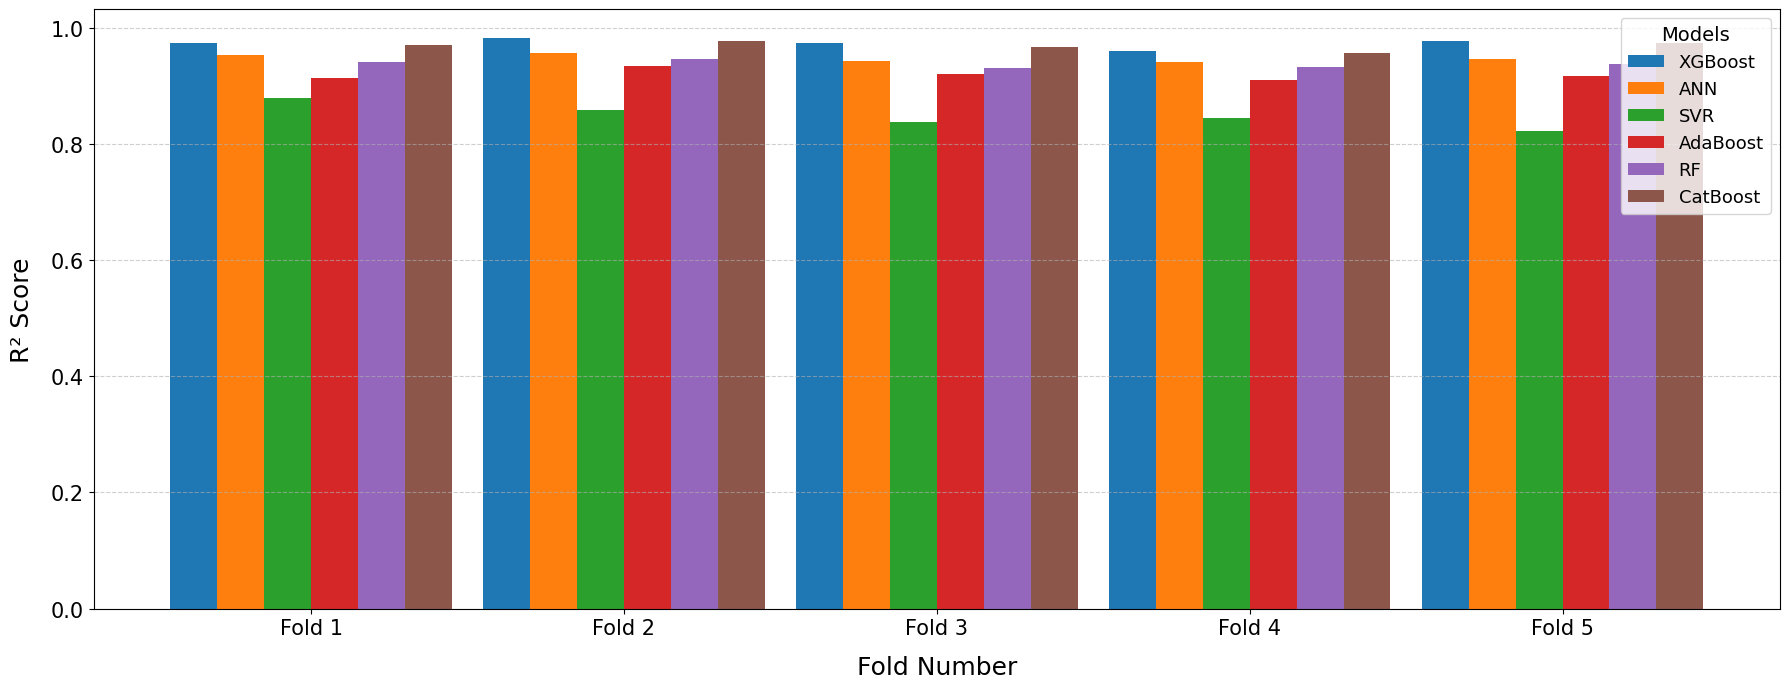

In [12]:

plt.figure(figsize=(18, 7))

n_folds = 5
n_models = len(models)
x = np.arange(n_folds)
width = 0.15

colors = ["tab:blue", "tab:orange", "tab:green",
          "tab:red", "tab:purple", "tab:brown"]

for i, model_name in enumerate(model_names):
    plt.bar(
        x + i * width,
        fold_r2[model_name],
        width,
        label=model_name,
        color=colors[i]
    )

# Axis labels
plt.xlabel("Fold Number", fontsize=18, labelpad=12)
plt.ylabel("R² Score", fontsize=18, labelpad=12)

# Tick labels
plt.xticks(
    x + width * 2.5,
    [f"Fold {i}" for i in range(1, 6)],
    fontsize=15
)
plt.yticks(fontsize=15)

# Legend
plt.legend(
    title="Models",
    fontsize=13,
    title_fontsize=14
)

plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


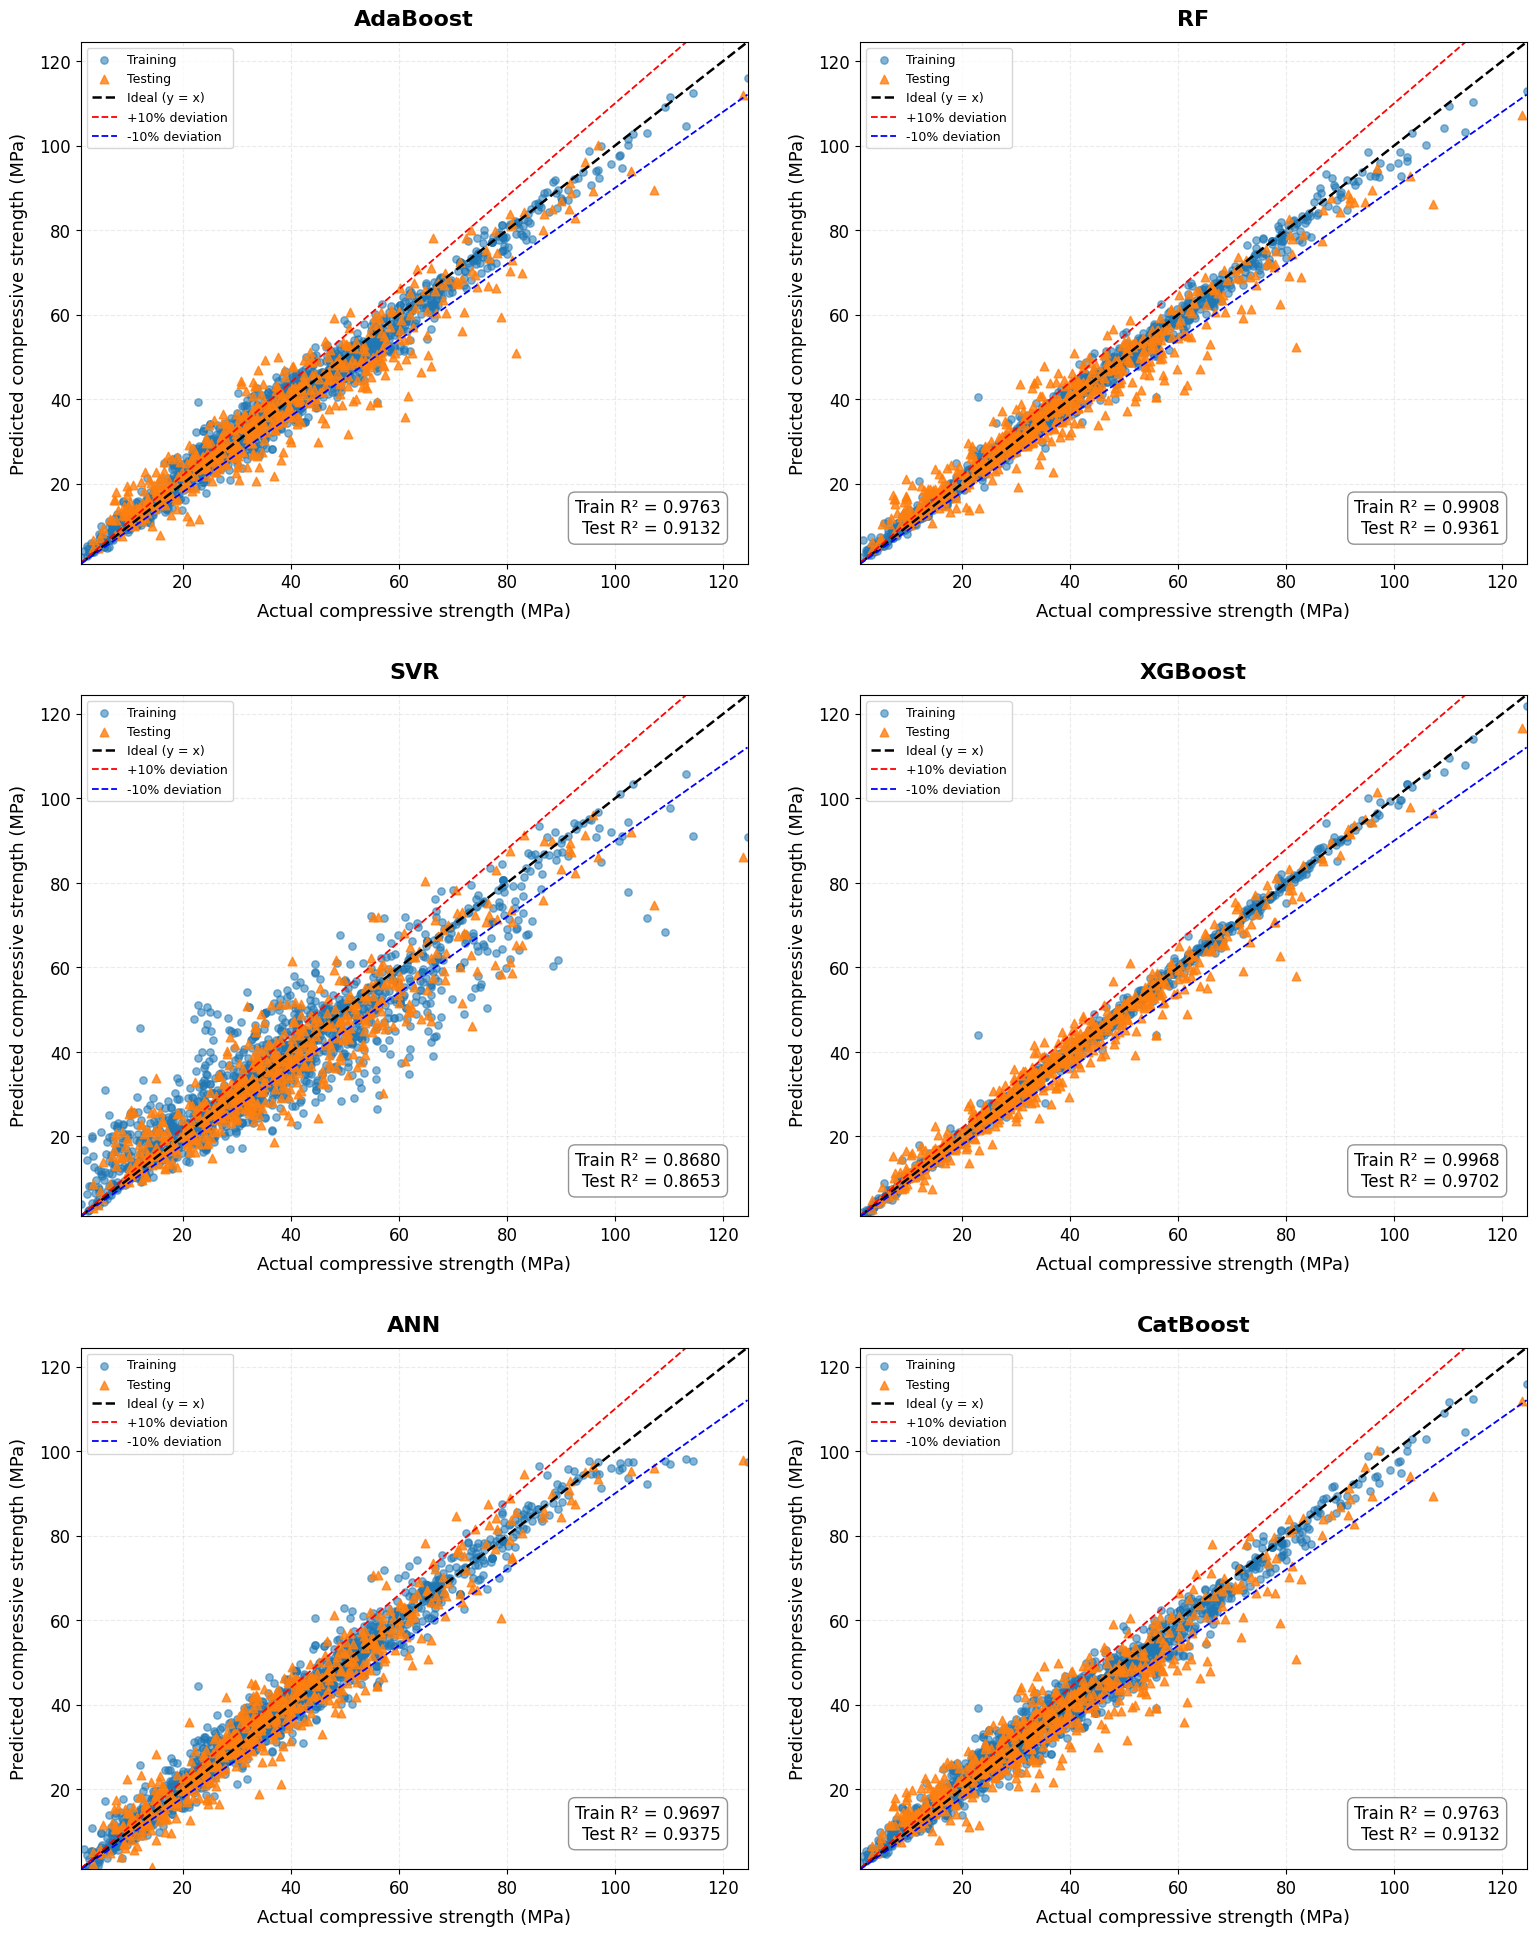

In [23]:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import r2_score

models = {
    
    "AdaBoost": model_AdaBoostRegressor,
    "RF": model_RandomForestRegressor,
    "SVR": model_SVR,
    "XGBoost": model_XGBRegressor,
    "ANN": model_MLPRegressor,
        
    "CatBoost": model_CatBoostRegressor
}

# Create 3x2 subplot layout
fig, axes = plt.subplots(3, 2, figsize=(16, 20))
axes = axes.flatten()

# Common axis limits for all models
min_val = min(y_train.min(), y_test.min())
max_val = max(y_train.max(), y_test.max())

x_vals = np.linspace(min_val, max_val, 200)

for ax, (model_name, model) in zip(axes, models.items()):

    # Predictions
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    # R2 scores
    r2_train = r2_score(y_train, y_pred_train)
    r2_test = r2_score(y_test, y_pred_test)

    # Scatter plots
    ax.scatter(
        y_train, y_pred_train,
        label="Training",
        alpha=0.55,
        s=28,
        marker="o"
    )

    ax.scatter(
        y_test, y_pred_test,
        label="Testing",
        alpha=0.8,
        s=38,
        marker="^"
    )

    # Ideal prediction line
    ax.plot(
        x_vals, x_vals,
        "k--",
        linewidth=1.8,
        label="Ideal (y = x)"
    )

    # ±10% deviation lines
    ax.plot(
        x_vals, 1.10 * x_vals,
        "r--",
        linewidth=1.3,
        label="+10% deviation"
    )

    ax.plot(
        x_vals, 0.90 * x_vals,
        "b--",
        linewidth=1.3,
        label="-10% deviation"
    )

    # R2 annotation
    textstr = (
        f"Train R² = {r2_train:.4f}\n"
        f"Test R² = {r2_test:.4f}"
    )

    ax.text(
        0.96, 0.05,
        textstr,
        transform=ax.transAxes,
        fontsize=12,
        verticalalignment="bottom",
        horizontalalignment="right",
        bbox=dict(
            facecolor="white",
            alpha=0.85,
            edgecolor="gray",
            boxstyle="round,pad=0.4"
        )
    )

    # Axis labels and title
    ax.set_xlabel(
        "Actual compressive strength (MPa)",
        fontsize=13,
        labelpad=8
    )

    ax.set_ylabel(
        "Predicted compressive strength (MPa)",
        fontsize=13,
        labelpad=8
    )

    ax.set_title(model_name, fontsize=16, fontweight="bold", pad=12)

    # Tick labels
    ax.tick_params(axis="both", labelsize=12)

    # Same scale for all subplots
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)

    ax.grid(alpha=0.25, linestyle="--")

    ax.legend(fontsize=9, loc="upper left", frameon=True)

# Overall layout
fig.tight_layout(pad=3.0)

plt.show()


In [23]:
# Taylor diagram 

import numpy as np
import matplotlib.pyplot as plt
import matplotlib

# -------------------------
# Taylor Diagram Class
# -------------------------
class TaylorDiagram:
    def __init__(self, refstd, fig=None, rect=111, label='Reference'):
        self.refstd = refstd

        tr = np.pi / 2
        t = np.linspace(0, tr)

        if fig is None:
            fig = plt.figure(figsize=(7, 6))

        self.fig = fig
        self.ax = fig.add_subplot(rect, polar=True)

        # Set limits
        self.ax.set_xlim([0, tr])

        # Correlation labels
        rs = np.concatenate((np.linspace(0, 0.9, 10), [0.95, 1.0]))
        self.ax.set_thetagrids(np.degrees(np.arccos(rs)),
                               labels=[f"{r:.2f}" for r in rs])

        # Radius grid (standard deviation)
        self.ax.set_rgrids(np.linspace(0, refstd * 1.5, 7))

        # Plot reference point
        self.ax.plot(0, refstd, 'ko', label=label)

    def add_sample(self, stddev, corrcoef, label, marker='o', color='r'):
        theta = np.arccos(corrcoef)
        self.ax.plot(theta, stddev, marker=marker, color=color, label=label)

    def add_contours(self, levels=5, **kwargs):
        rs, ts = np.meshgrid(np.linspace(0, self.refstd * 1.5, 100),
                             np.linspace(0, np.pi/2, 100))

        corr = np.cos(ts)
        rmse = np.sqrt(self.refstd**2 + rs**2 - 2*self.refstd*rs*corr)

        contours = self.ax.contour(ts, rs, rmse, levels, **kwargs)
        return contours


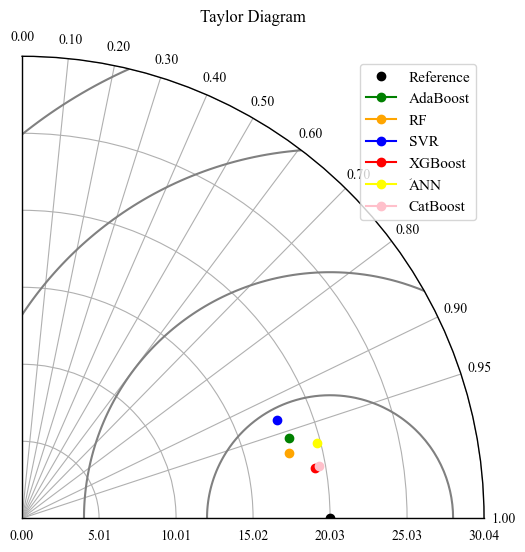

In [24]:
# Taylor diagram 

ref_std = np.std(y_test)
std_pred = np.std(y_pred)
corr = np.corrcoef(y_test, y_pred)[0, 1]

fig = plt.figure(figsize=(7, 6))
dia = TaylorDiagram(ref_std, fig=fig, label="Reference")

dia.add_sample(np.std(y_AdaBoostRegressor), np.corrcoef(y_test, y_AdaBoostRegressor)[0,1], label="AdaBoost", color="green")
dia.add_sample(np.std(y_RandomForestRegressor), np.corrcoef(y_test, y_RandomForestRegressor)[0,1], label="RF", color="orange")
dia.add_sample(np.std(y_SVR), np.corrcoef(y_test, y_SVR)[0,1], label="SVR", color="blue")
dia.add_sample(np.std(y_XGBRegressor), np.corrcoef(y_test, y_XGBRegressor)[0,1], label="XGBoost", color="red")
dia.add_sample(np.std(y_MLPRegressor), np.corrcoef(y_test, y_MLPRegressor)[0,1], label="َANN", color="yellow")
dia.add_sample(np.std(y_CatBoostRegressor), np.corrcoef(y_test, y_CatBoostRegressor)[0,1], label="CatBoost", color="pink")

dia.add_contours(levels=5, colors='0.5')

plt.legend(loc='upper right')
plt.title("Taylor Diagram")
plt.show()